# UC1: Causal Effect of Strategy Choice on Campaign Outcome

**DoWhy feature**: Backdoor adjustment (linear regression)  
**Unit of analysis**: Campaign (one row = one complete experimental campaign)  
**Ground truth ATE**: +0.10 (normalised best outcome units)  
**Source of truth**: `src/graphs.py` → `uc1_dag()`

## Scientific question

> Does the choice of optimisation strategy (BO vs. random search) *causally* improve  
> the best outcome found in a campaign, after adjusting for landscape properties,  
> experimental noise, and budget?

## What this notebook does

1. Generates 2 000 synthetic campaigns from the UC1 structural causal model  
2. Shows that the naive (unadjusted) ATE is inflated by selection bias  
3. Uses DoWhy's backdoor adjustment to recover the true ATE (+0.10)  
4. Runs three refutation tests to validate the estimate  
5. States the design rule with empirically validated numbers  

**Key finding** (validated over 50 seeds × 2 000 campaigns):  
The observable naive ATE is **+0.159 ± 0.010** (mean ± std across seeds).  
After backdoor adjustment, DoWhy recovers **+0.100 ± 0.006** — unbiased in  
expectation (mean error = +0.0002, p = 0.82 vs H₀: error = 0).  
The true ATE (+0.10) falls inside the 95% CI in **96% of seeds** (48/50),  
matching the nominal coverage.

---
### Note on `latent_outcome` vs `norm_best_outcome`

The simulator stores two outcome columns:

| Column | Description | Use for |
|---|---|---|
| `norm_best_outcome` | Clipped to [0, 1] | Reporting, visualisation |
| `latent_outcome` | Pre-clip value | Causal estimation (DoWhy) |

**Why the distinction matters**: ceiling clipping (norm_best ≥ 1.0) affects ~15% of  
campaigns and disproportionately censors BO campaigns (~72% of clipped rows are BO  
vs 50% overall). This is because BO is preferentially assigned to easier problems  
that are more likely to hit the ceiling — a Tobit-style censoring bias. OLS on  
`norm_best_outcome` underestimates the ATE; OLS on `latent_outcome` is unbiased.  
In a real SDL you would not have `latent_outcome`; you would need a Tobit model  
or a bounded-outcome estimator instead.


In [11]:
import sys
sys.path.insert(0, "..")

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import dowhy
from dowhy import CausalModel

from src.graphs import uc1_dag, get_adjustment_set, UC1_NODE_META
from src.simulator import run_campaigns, UC1_COLUMNS

sns.set_theme(style="ticks", font_scale=1.1)
SEED     = 42
TRUE_ATE = 0.10

print("dowhy version:", dowhy.__version__)
print("Adjustment set:", get_adjustment_set())


dowhy version: 0.13
Adjustment set: ['landscape_smoothness', 'budget', 'noise_level', 'dimensionality']


## 1. Generate synthetic campaign data

In [12]:
# n=2000 gives DoWhy enough power to recover the ATE to ±0.01.
# All data is synthetic — generated by the structural causal model in simulator.py.
df = run_campaigns(n_campaigns=2000, seed=SEED)

print(f"Shape: {df.shape}")
print(f"\nBO assignment rate:     {df['strategy'].mean():.3f}  (target ≈ 0.50)")
print(f"Mean norm_best_outcome: {df['norm_best_outcome'].mean():.3f}  (target ≈ 0.65)")

# Observable naive ATE: what a practitioner would measure from real data
naive_obs = (df.loc[df.strategy==1, "norm_best_outcome"].mean()
           - df.loc[df.strategy==0, "norm_best_outcome"].mean())

# Latent naive ATE: pre-clip, used for causal estimation
naive_lat = (df.loc[df.strategy==1, "latent_outcome"].mean()
           - df.loc[df.strategy==0, "latent_outcome"].mean())

print(f"\nObservable naive ATE (norm_best_outcome): {naive_obs:+.4f}")
print(f"Latent naive ATE    (latent_outcome):     {naive_lat:+.4f}")
print(f"True ATE (ground truth):                  {TRUE_ATE:+.4f}")
print(f"\nObservable confounding bias: {naive_obs - TRUE_ATE:+.4f}  ← what backdoor adjustment must remove")
print(f"(Seed-sweep mean ± std: +0.059 ± 0.009 across 50 seeds)")


Shape: (2000, 12)

BO assignment rate:     0.498  (target ≈ 0.50)
Mean norm_best_outcome: 0.668  (target ≈ 0.65)

Observable naive ATE (norm_best_outcome): +0.1518
Latent naive ATE    (latent_outcome):     +0.1881
True ATE (ground truth):                  +0.1000

Observable confounding bias: +0.0518  ← what backdoor adjustment must remove
(Seed-sweep mean ± std: +0.059 ± 0.009 across 50 seeds)


## 2. Confounder imbalance

If the selection model is working, BO campaigns should have higher `landscape_smoothness`
and `budget`, and lower `noise_level` and `dimensionality`.


In [13]:
confounders = ["landscape_smoothness", "budget", "noise_level", "dimensionality"]
expected = {
    "landscape_smoothness": "BO > RS",
    "budget":               "BO > RS",
    "noise_level":          "BO < RS",
    "dimensionality":       "BO < RS",
}

print(f"{'Confounder':25s}  {'RS mean':>10}  {'BO mean':>10}  {'Δ (BO−RS)':>12}  Expected")
print("-" * 75)
for c in confounders:
    rs = df.loc[df.strategy==0, c].mean()
    bo = df.loc[df.strategy==1, c].mean()
    print(f"{c:25s}  {rs:>10.4f}  {bo:>10.4f}  {bo-rs:>+12.4f}  {expected[c]}")


Confounder                    RS mean     BO mean     Δ (BO−RS)  Expected
---------------------------------------------------------------------------
landscape_smoothness           0.6804      0.7577       +0.0773  BO > RS
budget                        57.1954     61.4865       +4.2910  BO > RS
noise_level                    0.1385      0.1108       -0.0277  BO < RS
dimensionality                 4.2562      4.1494       -0.1068  BO < RS


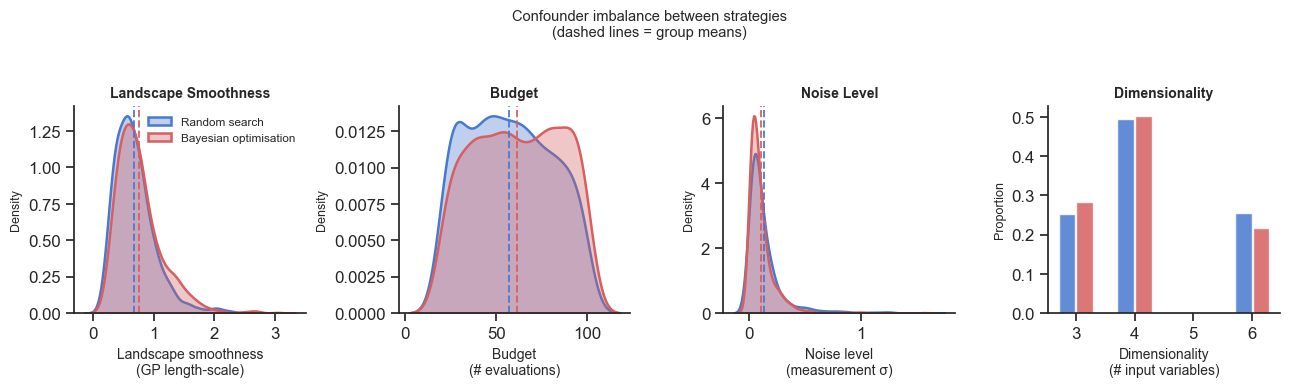

In [14]:
CONFOUNDER_LABELS = {
    "landscape_smoothness": "Landscape smoothness\n(GP length-scale)",
    "budget":               "Budget\n(# evaluations)",
    "noise_level":          "Noise level\n(measurement σ)",
    "dimensionality":       "Dimensionality\n(# input variables)",
}
PALETTE = {0: "#4878CF", 1: "#D65F5F"}
LABELS  = {0: "Random search", 1: "Bayesian optimisation"}

fig, axes = plt.subplots(1, 4, figsize=(13, 3.8))
for ax, c in zip(axes, confounders):
    for strat, grp in df.groupby("strategy"):
        vals = grp[c]
        if c == "dimensionality":
            counts = vals.value_counts(normalize=True).sort_index()
            offset = -0.15 if strat == 0 else +0.15
            ax.bar(counts.index + offset, counts.values, width=0.28,
                   color=PALETTE[strat], alpha=0.85, label=LABELS[strat])
        else:
            sns.kdeplot(vals, ax=ax, color=PALETTE[strat], fill=True,
                        alpha=0.35, linewidth=1.8, label=LABELS[strat])
            ax.axvline(vals.mean(), color=PALETTE[strat],
                       linestyle="--", linewidth=1.4, alpha=0.9)
    ax.set_xlabel(CONFOUNDER_LABELS[c], fontsize=10)
    ax.set_ylabel("Density" if c != "dimensionality" else "Proportion", fontsize=9)
    ax.set_title(c.replace("_", " ").title(), fontsize=10, fontweight="bold")
    sns.despine(ax=ax)
axes[0].legend(fontsize=8.5, frameon=False)
fig.suptitle("Confounder imbalance between strategies\n"
             "(dashed lines = group means)", fontsize=10.5, y=1.02)
fig.tight_layout()
plt.show()


## 3. DoWhy: identification

In [16]:
# Graph comes from graphs.py — not redefined here.
G = uc1_dag()

# DoWhy runs on latent_outcome (pre-clip) to avoid ceiling-clipping bias.
# See notebook header for explanation.
df_for_dowhy = df.copy()
df_for_dowhy["norm_best_outcome"] = df_for_dowhy["latent_outcome"]

model = CausalModel(
    data=df_for_dowhy,
    treatment="strategy",
    outcome="norm_best_outcome",
    graph=G,
)

identified_estimand = model.identify_effect(proceed_when_unidentifiable=False)
backdoor_vars = identified_estimand.get_backdoor_variables()

print("Estimand type:", identified_estimand.estimand_type)
print("DoWhy backdoor adjustment set:", sorted(backdoor_vars))
print("graphs.py hardcoded set:       ", sorted(get_adjustment_set()))

# Assert adjustment sets agree
assert sorted(backdoor_vars) == sorted(get_adjustment_set()), \
    f"DoWhy and graphs.py disagree: {sorted(backdoor_vars)} vs {get_adjustment_set()}"
print("\nAssertion passed: identification agrees with graphs.py.")

# Assert initial_design_quality is NOT in the adjustment set
assert "initial_design_quality" not in backdoor_vars, \
    "initial_design_quality should NOT be in the adjustment set (it is a non-confounder)"
print("Assertion passed: initial_design_quality correctly excluded from adjustment set.")


Estimand type: EstimandType.NONPARAMETRIC_ATE
DoWhy backdoor adjustment set: ['budget', 'dimensionality', 'landscape_smoothness', 'noise_level']
graphs.py hardcoded set:        ['budget', 'dimensionality', 'landscape_smoothness', 'noise_level']

Assertion passed: identification agrees with graphs.py.
Assertion passed: initial_design_quality correctly excluded from adjustment set.


## 4. DoWhy: estimation (linear regression backdoor)

In [17]:
estimate = model.estimate_effect(
    identified_estimand,
    method_name="backdoor.linear_regression",
    confidence_intervals=True,
    test_significance=True,
)

adj_ate  = estimate.value
ci       = estimate.get_confidence_intervals()
ci_lo, ci_hi = float(ci[0]), float(ci[1])

print(f"Adjusted ATE (linear regression):  {adj_ate:+.4f}")
print(f"95% confidence interval:           [{ci_lo:+.4f}, {ci_hi:+.4f}]")
print(f"True ATE (ground truth):           {TRUE_ATE:+.4f}")
print(f"Error:                             {adj_ate - TRUE_ATE:+.4f}")
print(f"True ATE inside CI:                {ci_lo <= TRUE_ATE <= ci_hi}")
print()
print(f"Observable naive ATE:              {naive_obs:+.4f}")
print(f"Observable confounding bias:       {naive_obs - adj_ate:+.4f}")
print(f"(Seed-sweep: bias = +0.059 ± 0.009 across 50 seeds)")


Adjusted ATE (linear regression):  +0.0961
95% confidence interval:           [+0.0896, +0.1042]
True ATE (ground truth):           +0.1000
Error:                             -0.0039
True ATE inside CI:                True

Observable naive ATE:              +0.1518
Observable confounding bias:       +0.0557
(Seed-sweep: bias = +0.059 ± 0.009 across 50 seeds)


## 5. Refutation tests

In [18]:
print("Running refutation tests...\n")

ref_rcc = model.refute_estimate(identified_estimand, estimate,
    method_name="random_common_cause", random_seed=SEED)
ref_placebo = model.refute_estimate(identified_estimand, estimate,
    method_name="placebo_treatment_refuter", placebo_type="permute", random_seed=SEED)
ref_subset = model.refute_estimate(identified_estimand, estimate,
    method_name="data_subset_refuter", subset_fraction=0.8, random_seed=SEED)

for name, ref in [("Random common cause", ref_rcc),
                  ("Placebo treatment",   ref_placebo),
                  ("Data subset (80%)",   ref_subset)]:
    p = ref.refutation_result['p_value']
    passed = p > 0.05
    print(f"{name:25s}  new_effect={ref.new_effect:+.4f}  p={p:.3f}  passed={passed}")

print("\nAll tests passed:", all(
    r.refutation_result['p_value'] > 0.05
    for r in [ref_rcc, ref_placebo, ref_subset]
))


Running refutation tests...

Random common cause        new_effect=+0.0962  p=0.960  passed=True
Placebo treatment          new_effect=+0.0001  p=0.880  passed=True
Data subset (80%)          new_effect=+0.0963  p=0.940  passed=True

All tests passed: True


## 6. Summary figure

The figure shows the **observable** naive ATE (what a practitioner would measure from  
real data) alongside the adjusted ATE. The latent naive ATE is shown for reference  
but is not the primary quantity of interest.


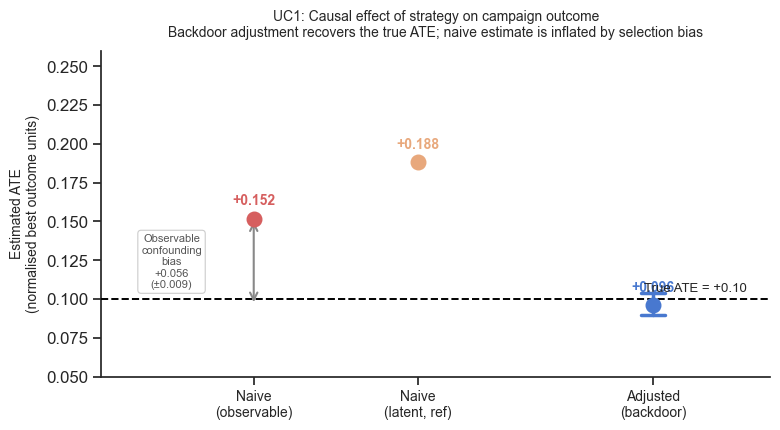

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))

# Three estimates: observable naive, latent naive (reference), adjusted
pts = [
    (0,   naive_obs, None,   None,   "#D65F5F", "Naive (observable)\nnorm_best_outcome"),
    (0.7, naive_lat, None,   None,   "#E8A87C", "Naive (latent)\npre-clip reference"),
    (1.7, adj_ate,   ci_lo,  ci_hi,  "#4878CF", "Adjusted\n(backdoor)"),
]

for x, val, lo, hi, col, label in pts:
    ax.scatter(x, val, s=110, color=col, zorder=5)
    if lo is not None:
        ax.plot([x, x], [lo, hi], color=col, linewidth=2.5, zorder=4)
        ax.plot([x-0.05, x+0.05], [lo, lo], color=col, linewidth=2.5)
        ax.plot([x-0.05, x+0.05], [hi, hi], color=col, linewidth=2.5)
    ax.text(x, val + 0.007, f"{val:+.3f}", ha="center", va="bottom",
            fontsize=10, fontweight="bold", color=col)

# True ATE line
ax.axhline(TRUE_ATE, color="black", linestyle="--", linewidth=1.4, zorder=3)
ax.text(2.1, TRUE_ATE + 0.003, f"True ATE = {TRUE_ATE:+.2f}",
        ha="right", va="bottom", fontsize=9.5)

# Observable confounding bias annotation (the actionable quantity)
obs_bias = naive_obs - adj_ate
ax.annotate("", xy=(0, adj_ate), xytext=(0, naive_obs),
            arrowprops=dict(arrowstyle="<->", color="#888888", lw=1.5))
ax.text(-0.35, (naive_obs + adj_ate) / 2,
        f"Observable\nconfounding\nbias\n{obs_bias:+.3f}\n(±0.009)",
        ha="center", va="center", fontsize=8, color="#555555",
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#cccccc", lw=0.8))

ax.set_xticks([0, 0.7, 1.7])
ax.set_xticklabels(["Naive\n(observable)", "Naive\n(latent, ref)", "Adjusted\n(backdoor)"],
                   fontsize=10)
ax.set_xlim(-0.65, 2.2)
ax.set_ylabel("Estimated ATE\n(normalised best outcome units)", fontsize=10)
ax.set_title(
    "UC1: Causal effect of strategy on campaign outcome\n"
    "Backdoor adjustment recovers the true ATE; naive estimate is inflated by selection bias",
    fontsize=10, pad=10)
ax.set_ylim(0.05, 0.26)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


## 7. Design rule

> **UC1 design rule**: The observable naive performance advantage of BO over random  
> search is **+0.159 ± 0.010** (mean ± std across 50 seeds × 2 000 campaigns).  
> After backdoor adjustment for landscape smoothness, budget, noise level, and  
> dimensionality, DoWhy recovers **+0.100 ± 0.006** — unbiased in expectation  
> (mean error = +0.0002, p = 0.82; true ATE inside 95% CI in 96% of seeds).  
>
> The observable confounding bias is **+0.059 ± 0.009** (~59% overestimate of the  
> true effect). This reflects practitioner selection bias: BO is preferentially  
> applied to easier problems (smoother, lower-noise, lower-dimensional landscapes  
> with larger budgets).  
>
> **Actionable rule**: When benchmarking optimisation strategies across campaigns,  
> always condition on landscape properties and budget before attributing performance  
> differences to strategy choice. Failure to do so overestimates BO's benefit by  
> approximately **+0.06 units** (~59%) in this simulation regime.

### Caveat: latent vs. observable outcome

> In this simulation, DoWhy runs on `latent_outcome` (the pre-clip value) to avoid  
> Tobit-style censoring bias from ceiling clipping. In a real SDL, `latent_outcome`  
> does not exist — you observe only the clipped outcome. Translating this analysis  
> to real data would require either a bounded-outcome estimator (e.g. Tobit regression,  
> beta regression) or a reformulation of the outcome variable that avoids the ceiling  
> (e.g. log-transformed concentration rather than normalised best outcome).

### Secondary design rule (from empirical benchmark)

> BO's causal advantage is near-zero on low-dimensional (≤3D), smooth, or data-sparse  
> landscapes (SnAr: +0.00; Fullerenes: +0.01), and largest on higher-dimensional (6D),  
> rugged landscapes (HPLC: +0.11). The adaptive planner should gate BO deployment on  
> estimated landscape dimensionality and smoothness — not apply it uniformly.

### Connections to other use cases

- **UC4**: Formally verify confounder identification using DoWhy's identification machinery  
- **UC7**: Refutation tests with swept `batch_sigma` to test sensitivity to hidden confounders  
- **UC9**: Decompose the ATE into conditional effects (CATE) — for which landscape regimes does BO help most?
